In [1]:
# !ffmpeg -y -loglevel error -i audio/noise_recording.m4a -ac 1 -ar 44100 -c:a pcm_s16le audio/noise_recording.wav

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy import signal
import IPython.display as ipd

# Clean Signal

In [3]:
fs_clean, clean_signal = wavfile.read("./audio/clean_speech.wav")
t_clean = np.arange(len(clean_signal)) / fs_clean

print("fs =",fs_clean)
print("Samples =",len(clean_signal))
print("Duration =",len(clean_signal)/fs_clean,"s")
print("signal shape =", clean_signal.shape) #mono signal, 1 channel
print("signal dtype =", clean_signal.dtype)

fs = 16000
Samples = 172343
Duration = 10.7714375 s
signal shape = (172343,)
signal dtype = int16


In [4]:
# int16 can store -32768 to 32767 -> convert to float before adding noise
clean = clean_signal.astype(np.float64)        # step 1: cast to float
clean = clean / np.max(np.abs(clean))          # step 2: peak normalize to [-1, 1]

print(clean.dtype, clean.min(), clean.max())   # should be float64, about -1 to 1

float64 -1.0 0.8294639276324585


Text(0.5, 1.0, 'original clean_signal after peak_normalization')

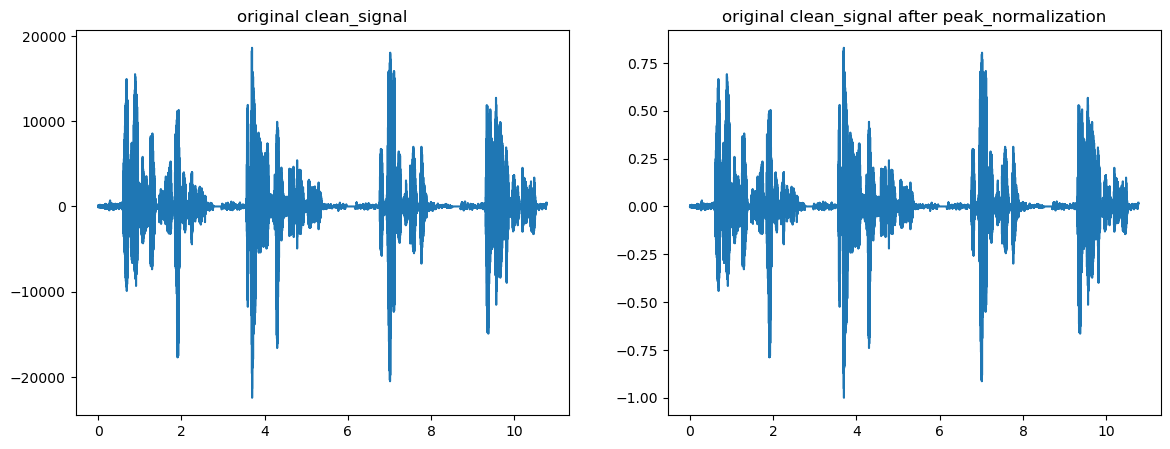

In [13]:
# print(clean)
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1); plt.plot(t_clean, clean_signal); plt.title("original clean_signal")
plt.subplot(1, 2, 2); plt.plot(t_clean, clean); plt.title("original clean_signal after peak_normalization")

# Noise Signal

In [6]:
fs_noise, noise_signal = wavfile.read("./audio/noise_recording.wav")
t_noise = np.arange(len(noise_signal)) / fs_noise

print("fs =",fs_noise)
print("Samples =",len(noise_signal))
print("Duration =",len(noise_signal)/fs_noise,"s")
print("signal shape =", noise_signal.shape) #mono signal, 1 channel
print("signal dtype =", noise_signal.dtype)

fs = 44100
Samples = 587001
Duration = 13.310680272108844 s
signal shape = (587001,)
signal dtype = int16


In [7]:
noise = noise_signal.astype(np.float64)
noise = noise / np.max(np.abs(noise))

Text(0.5, 1.0, 'original noise_signal after peak_normalization')

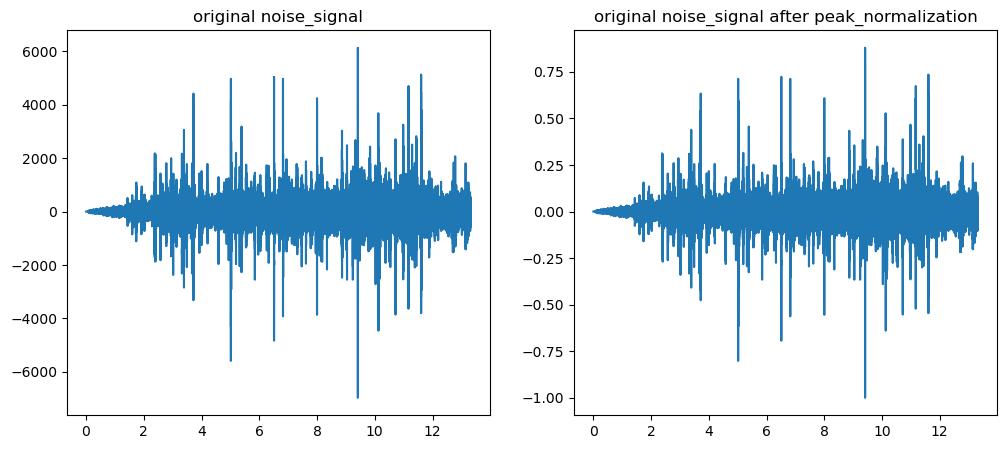

In [8]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1); plt.plot(t_noise, noise_signal); plt.title("original noise_signal")
plt.subplot(1, 2, 2); plt.plot(t_noise, noise); plt.title("original noise_signal after peak_normalization")

# Adding noise to clean signal

In [9]:
noise = noise[fs_noise*2:len(clean)+fs_noise*2]
print(len(noise), len(clean))   # both numbers should be the same

172343 172343


In [15]:
# noise_level = 0.5               # the number that controls how loud the noise is

noisy_speech = clean + noise

Clean


Noisy


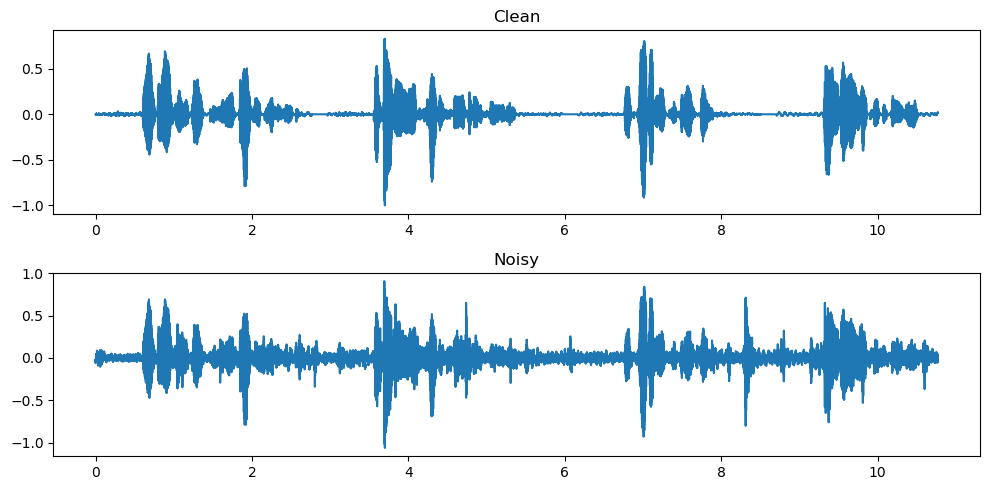

In [16]:
print("Clean")
ipd.display(ipd.Audio(clean, rate=fs_clean))
print("Noisy")
ipd.display(ipd.Audio(noisy_speech, rate=fs_clean))

plt.figure(figsize=(10, 5))
plt.subplot(2, 1, 1); plt.plot(t_clean, clean); plt.title("Clean")
plt.subplot(2, 1, 2); plt.plot(t_clean, noisy_speech); plt.title("Noisy")
plt.tight_layout()
plt.show()

In [12]:
# # save the noisy_speech
# import os
# os.makedirs("./audio/audio_run", exist_ok=True)       # make the folder if it doesn't exist

# noisy_save = noisy_speech / max(1, np.max(np.abs(noisy_speech)))   # only shrinks it if it goes above 1
# wavfile.write("./audio/audio_run/noisy_speech.wav", fs_clean, (noisy_save * 32767).astype(np.int16))

# Audio Noise Reduction

1. EDA

In [18]:
def spectrum(x, fs, nfft = -1):
  N = len(x)
  if nfft == -1:
    nfft = N
  X = np.fft.fft(x, nfft)
  X = X[:N//2]
  mag = np.abs(X) *2/N
  mag[-1] = mag[-1]/2
  mag[0]  = mag[0]/2

  freq = np.arange(len(mag)) * fs/N
  return freq, mag

In [19]:
fs, x = wavfile.read("./audio/audio_run/noisy_speech.wav")
t = np.arange(len(x)) /fs
print("fs noisy: ", fs)

fs noisy:  16000


Text(0, 0.5, 'amplitude')

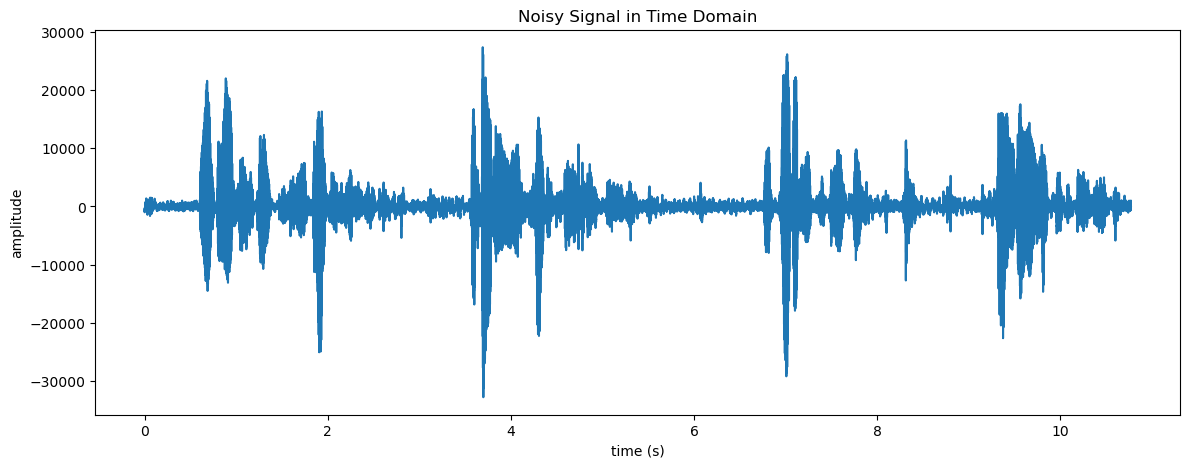

In [22]:
# plot in time domain
plt.figure(figsize=(14, 5))
plt.plot(t, x)
plt.title("Noisy Signal in Time Domain")
plt.xlabel("time (s)")
plt.ylabel("amplitude")

Text(0, 0.5, 'magnitude')

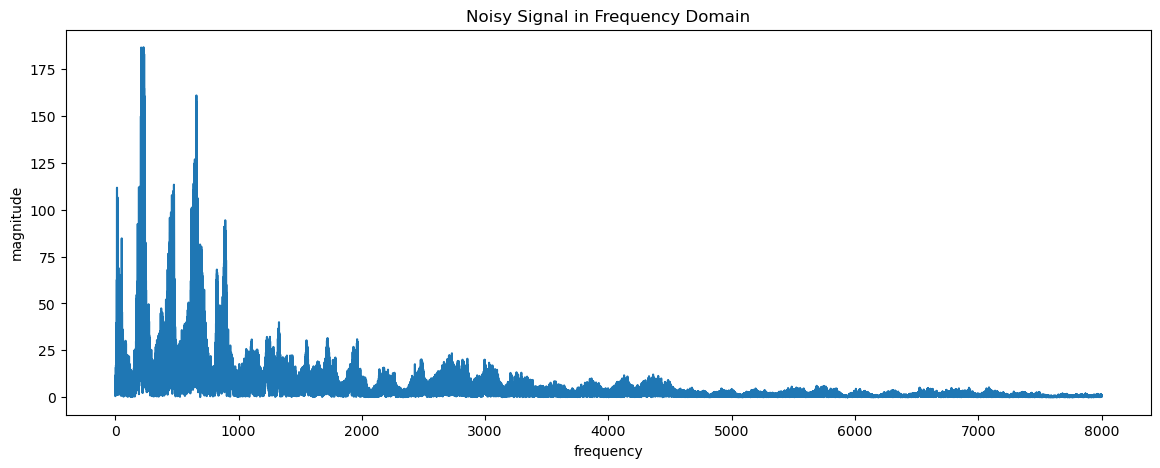

In [ ]:
# plot in Frequency Domain
freq, mag = spectrum(x, fs)
plt.figure(figsize=(14, 5))
plt.plot(freq, mag)
plt.title("Noisy Signal in Frequency Domain")
plt.xlabel("frequency")
plt.ylabel("magnitude")

total samples =  172343


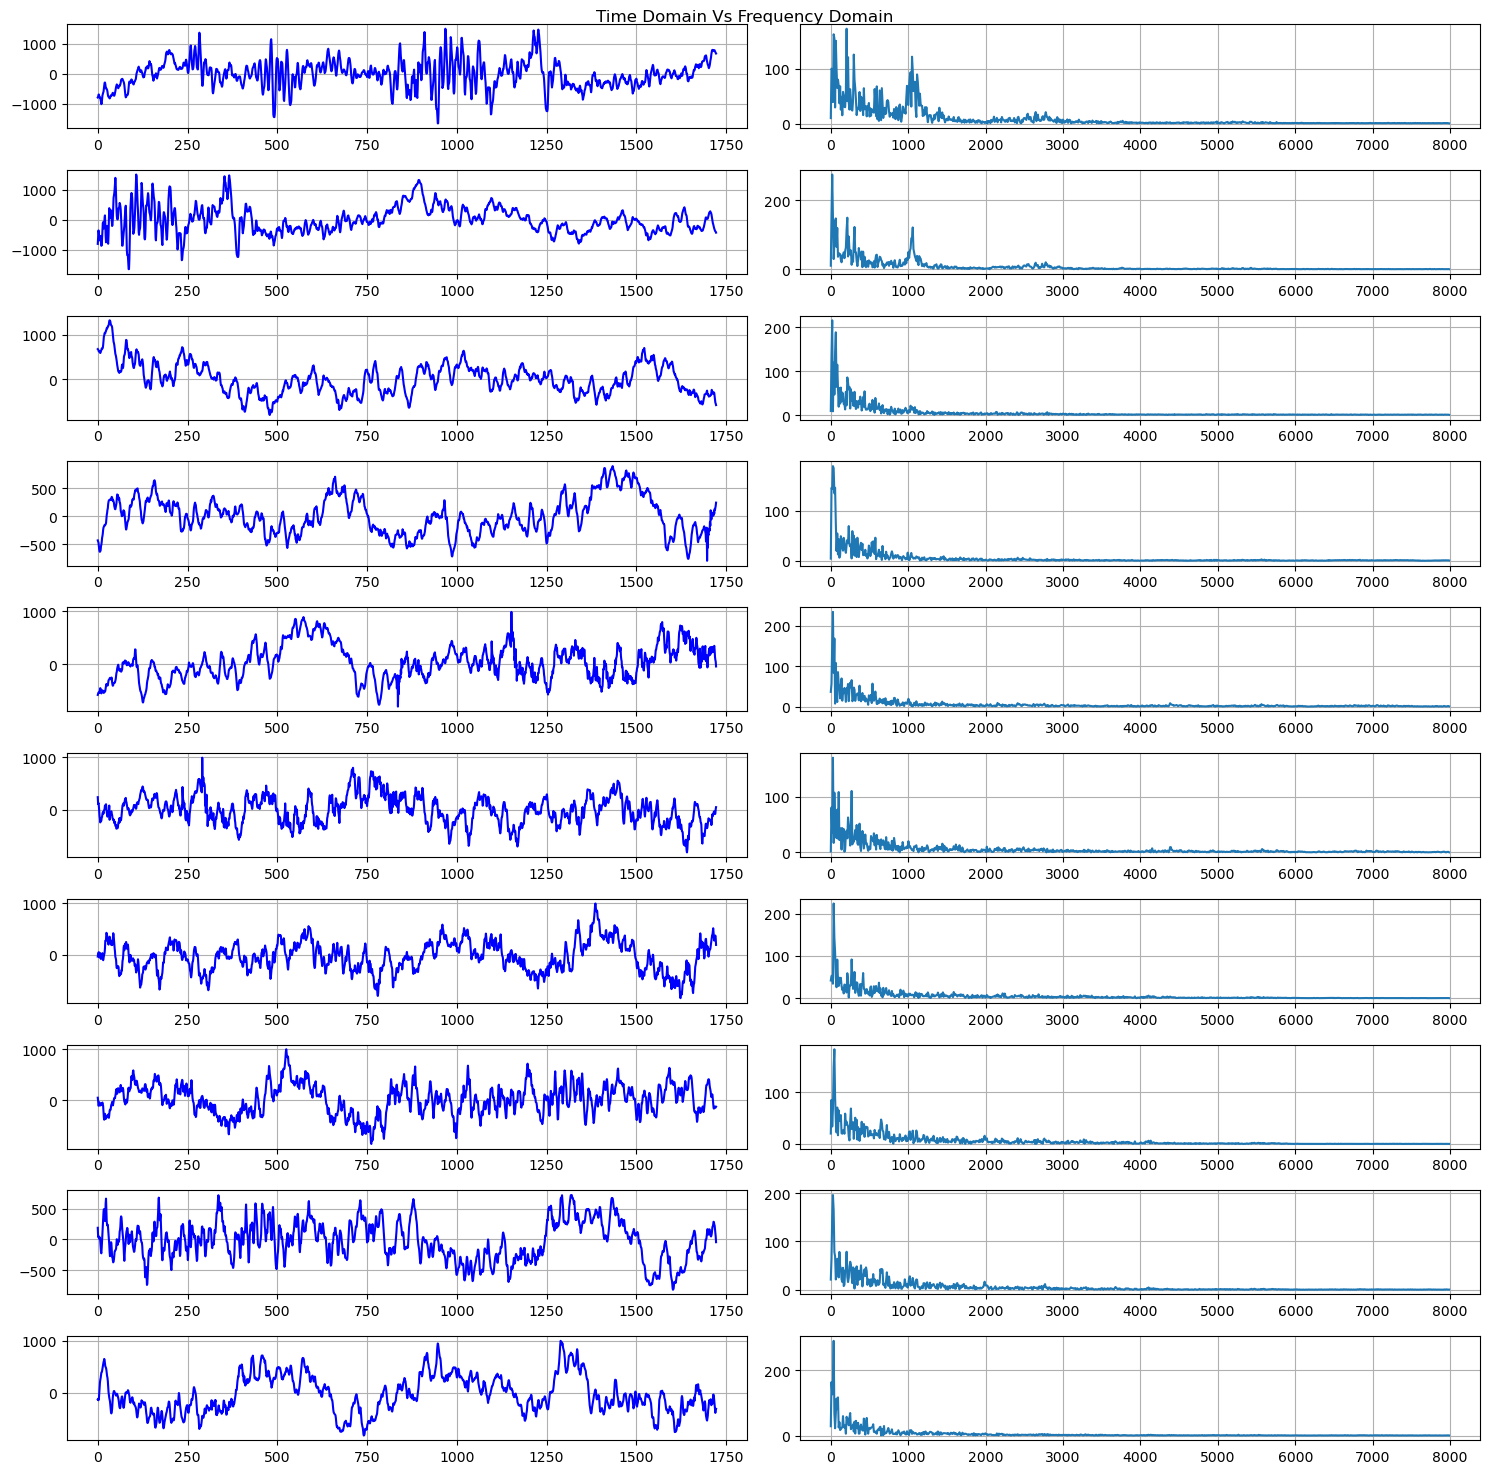

In [43]:
num_frame = 100
total_samples = len(noisy_speech) #N
frame_length = total_samples // num_frame #L
hop = int(0.5*frame_length)

print("total samples = ",total_samples)

p0 = 0
p1 = frame_length

plt.figure(figsize=(15, 15))

index = 1
for i in range(1, 11):
  x_win = x[p0:p1]
  plt.subplot(10, 2, index)
  plt.plot(x_win, color = "b")
  plt.grid()

  index = index + 1
  freq_win, mag_win = spectrum(x_win, fs)
  plt.subplot(10, 2, index)
  plt.plot(freq_win, mag_win)
  plt.grid()
  
  p0 += hop
  p1 += hop
  index = index + 1
plt.suptitle("Time Domain Vs Frequency Domain")
plt.tight_layout()